# Legnini - Spatial scale-dependent Moran analysis (Fig. 3B-C)

Reproduces Figure 3B-C of InterScale on the SHH example organoid (`slide4_B2-2`):

- **B**: expression of ventral-to-dorsal marker genes along the SHH gradient.
- **C**: Moran's I of each gene on spatial kNN graphs of increasing size k and the area under the Moran curve
  (AUC, trapezoidal rule over k).

All Moran's I curves and AUCs in Fig. 3C are computed on `slide4_B2-2` only (not averaged across sections);
the last section of this notebook shows the AUC across all SHH sections.

Localized genes lose spatial autocorrelation quickly with k (large ΔI, low AUC); genes organized at tissue scale
keep it (small ΔI, high AUC).

**Note:** the published panel uses k = 4, 8, 16, 32, 64, 128 and a single organoid; the Methods text lists
k = 4 … 64. With k up to 128 on `slide4_B2-2` the published values are reproduced.

Set `GRAPH = "radius"` to use radius graphs instead of kNN graphs. The radii are matched to `KS` (median distance
to the k-th nearest neighbor over all sections), so both graph types cover comparable neighborhood sizes.
The published Fig. 3C values are reproduced with `GRAPH = "knn"`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yaml

import matplotlib.pyplot as plt

import scanpy as sc

ROOT = Path.cwd()
while not (ROOT / "src" / "tl" / "moran.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from inside the InterScale_reproducibility repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.tl import auc_from_profile, moran_profile, radii_from_knn  # noqa: E402

## Configuration

In [2]:
DATA = "legnini23"
LEGNINI23 = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/data/legnini23.h5ad"

with open(ROOT / "figures" / "config.yml") as f:
    config = yaml.safe_load(f)

PLOT_CFG = config["plot_configs"]["general"]
CMAP = config["palettes"]["continuous"]
SLIDE = config["slide_examples"][DATA]["SSH"]  # slide4_B2-2
# global (persistent) vs. local (fast-decaying) genes, colored like the SHH rings: closest / furthest from source
COLOR_GLOBAL = config["palettes"][DATA]["ring_4"]
COLOR_LOCAL = config["palettes"][DATA]["ring_1"]
COLOR_OTHER = "#BBBBBB"

plt.rcParams.update({"font.family": PLOT_CFG["font_family"], "figure.dpi": PLOT_CFG["dpi"]})

LAYER = "log1p_norm"
LIBRARY_KEY = "sample"
KS = (4, 8, 16, 32, 64, 128)
GRAPH = "knn"  # "knn" or "radius"
FIG_DIR = ROOT / "figures" / DATA / "moran_scale" / GRAPH
FIG_DIR.mkdir(parents=True, exist_ok=True)

# dorsoventral patterning genes, ordered ventral -> dorsal along the SHH gradient
GENES = config["gene_sets"][DATA]["dorsoventral"]
GENE_GROUP = {"NKX6.1": "global", "IRX3": "global", "OLIG2": "local", "NKX2.2": "local"}
GROUP_COLOR = {"global": COLOR_GLOBAL, "local": COLOR_LOCAL}
# one color per gene for the Moran's I curves
GENE_COLORS = config["palettes"][DATA]["genes"]

## Load data

In [3]:
adata = sc.read_h5ad(LEGNINI23)
adata_slide = adata[adata.obs[LIBRARY_KEY] == SLIDE].copy()
print(f"{SLIDE}: {adata_slide.n_obs} cells, condition = {adata_slide.obs['condition'].unique().tolist()}")

# graph settings shared by all Moran computations below
if GRAPH == "knn":
    SCALE_COL, SCALES, XLABEL = "k", list(KS), "Number of neighbors (k)"
else:
    SCALE_COL, XLABEL = "radius", "Radius (coordinate units, px)"
    SCALES = list(radii_from_knn(adata, ks=KS, library_key=LIBRARY_KEY))  # prints the radius used per k
GRAPH_KW = dict(graph=GRAPH, ks=KS, radii=SCALES if GRAPH == "radius" else None)

slide4_B2-2: 1779 cells, condition = ['SHH']


## Moran's I across neighborhood sizes

In [4]:
prof = moran_profile(adata_slide, library_key=LIBRARY_KEY, genes=GENES, layer=LAYER, **GRAPH_KW)
auc = auc_from_profile(prof).sort_values("auc", ascending=False).reset_index(drop=True)
I = prof.pivot(index="feature", columns=SCALE_COL, values="I").loc[GENES, SCALES]
auc["delta_I"] = auc["feature"].map(I[SCALES[0]] - I[SCALES[-1]])

prof.to_csv(FIG_DIR / f"moran_profile_{SLIDE}.csv", index=False)
auc.to_csv(FIG_DIR / f"moran_auc_{SLIDE}.csv", index=False)
display(I.round(2))
display(auc.round(2))

k,4,8,16,32,64,128
feature,,,,,,
SHH,0.70,0.67,0.61,0.53,0.45,0.34
NKX2.2,0.64,0.57,0.48,0.39,0.30,0.22
NKX6.1,0.78,0.76,0.72,0.68,0.62,0.53
PAX6,0.78,0.74,0.69,0.63,0.55,0.45
OLIG2,0.64,0.58,0.51,0.42,0.32,0.21
IRX3,0.56,0.55,0.52,0.48,0.42,0.34
DBX2,0.67,0.65,0.62,0.56,0.48,0.40


,feature,auc,auc_norm,delta_I
0,NKX6.1,77.85,0.63,0.25
1,PAX6,70.24,0.57,0.33
2,DBX2,62.02,0.50,0.27
3,SHH,58.27,0.47,0.36
4,IRX3,52.90,0.43,0.22
5,OLIG2,42.99,0.35,0.43
6,NKX2.2,41.39,0.33,0.42


## Figure 3B: marker genes along the SHH gradient

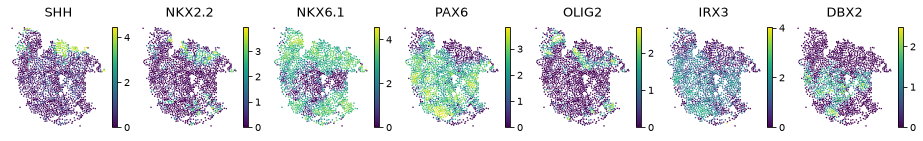

In [5]:
coords = adata_slide.obsm["spatial"]
X = adata_slide[:, GENES].layers[LAYER]
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)

fig, axes = plt.subplots(1, len(GENES), figsize=(2.2 * len(GENES), 2.6))
for j, (ax, g) in enumerate(zip(axes, GENES)):
    order = np.argsort(X[:, j])  # draw expressing cells on top
    sca = ax.scatter(coords[order, 0], coords[order, 1], c=X[order, j], s=2, cmap=CMAP, linewidths=0)
    fig.colorbar(sca, ax=ax, fraction=0.046, pad=0.02)
    ax.set_title(g, fontsize=PLOT_CFG["legend_fontsize"])
    ax.set_aspect("equal")
    ax.invert_yaxis()  # image orientation, as in squidpy.pl.spatial_scatter
    ax.axis("off")
plt.savefig(FIG_DIR / f"fig3b_markers_{SLIDE}.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / f"fig3b_markers_{SLIDE}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

## Figure 3C: Moran's I curves and AUC (`slide4_B2-2`)

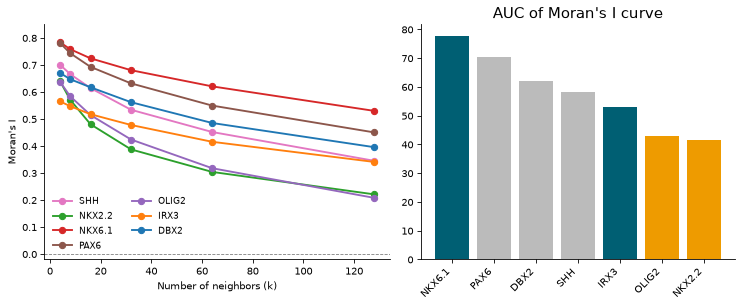

In [6]:
def gene_color(g):
    return GROUP_COLOR.get(GENE_GROUP.get(g), COLOR_OTHER)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})

# left: Moran's I vs. k
ax = axes[0]
for g in GENES:
    ax.plot(SCALES, I.loc[g], color=GENE_COLORS[g], marker="o", ms=6, lw=1.8, label=g)
ax.axhline(0, ls="--", lw=0.8, color="grey")
ax.set_xlabel(XLABEL)
ax.set_ylabel("Moran's I")
ax.set_ylim(-0.02, max(0.85, I.values.max() + 0.05))
ax.legend(ncol=2, frameon=False, fontsize=9, loc="lower left")

# right: AUC bar plot
ax = axes[1]
ax.bar(auc["feature"], auc["auc"], color=[gene_color(g) for g in auc["feature"]])
ax.set_title("AUC of Moran's I curve", fontsize=PLOT_CFG["title_fontsize"])
ax.tick_params(axis="x", rotation=45)
for lbl in ax.get_xticklabels():
    lbl.set_ha("right")

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"fig3c_moran_scale_{SLIDE}.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / f"fig3c_moran_scale_{SLIDE}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

## Moran's I per section

The published panel shows one organoid. Here the same seven genes are evaluated in every section separately
(SHH and Ctrl). Genes that are not expressed in a section have undefined Moran's I (NaN) there.

In [7]:
prof_all = moran_profile(adata, library_key=LIBRARY_KEY, genes=GENES, layer=LAYER, per_library=True, **GRAPH_KW)
section_condition = adata.obs.groupby(LIBRARY_KEY, observed=True)["condition"].first().astype(str)
prof_all["condition"] = prof_all["library"].map(section_condition)
prof_all.to_csv(FIG_DIR / "moran_profile_per_section.csv", index=False)
print(prof_all.groupby("condition")["library"].nunique())
if GRAPH == "radius":
    # fraction of cells without any neighbor within the radius (they shrink Moran's I towards 0)
    display(prof_all.groupby(["library", "radius"])["frac_isolated"].first().unstack().round(3))

condition
Ctrl     6
SHH     11
Name: library, dtype: int64


## Moran's I curves: average across SHH vs. Ctrl sections

Mean ± SD over sections of each condition (sections where the gene is not expressed are excluded).

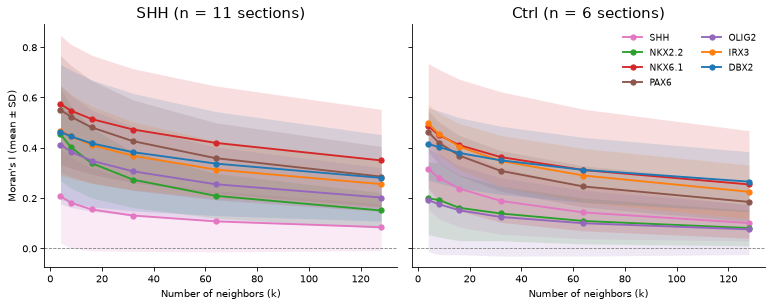

In [8]:
CONDITIONS = ["SHH", "Ctrl"]
summary = (
    prof_all.groupby(["condition", "feature", SCALE_COL])["I"]
    .agg(mean="mean", sd="std", n="count")
    .reset_index()
)
summary.to_csv(FIG_DIR / "moran_profile_mean_by_condition.csv", index=False)

fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5.2 * len(CONDITIONS), 4.2), sharey=True)
for ax, cond in zip(axes, CONDITIONS):
    n_sec = prof_all.loc[prof_all["condition"] == cond, "library"].nunique()
    for g in GENES:
        s = summary[(summary["condition"] == cond) & (summary["feature"] == g)].sort_values(SCALE_COL)
        ax.plot(s[SCALE_COL], s["mean"], color=GENE_COLORS[g], marker="o", ms=5, lw=1.8, label=g)
        ax.fill_between(s[SCALE_COL], s["mean"] - s["sd"], s["mean"] + s["sd"], color=GENE_COLORS[g], alpha=0.15, lw=0)
    ax.axhline(0, ls="--", lw=0.8, color="grey")
    ax.set_title(f"{cond} (n = {n_sec} sections)", fontsize=PLOT_CFG["title_fontsize"])
    ax.set_xlabel(XLABEL)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Moran's I (mean ± SD)")
axes[-1].legend(ncol=2, frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "moran_curves_shh_vs_ctrl.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "moran_curves_shh_vs_ctrl.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

In [9]:
# number of sections contributing per gene (genes can be unexpressed in some Ctrl sections)
summary[summary[SCALE_COL] == SCALES[0]].pivot(index="feature", columns="condition", values="n").loc[GENES]

condition,Ctrl,SHH
feature,,
SHH,6,11
NKX2.2,6,11
NKX6.1,6,11
PAX6,6,11
OLIG2,5,11
IRX3,6,11
DBX2,6,11


## AUC across SHH sections

Does the local / global ordering of the example slide hold in the other SHH sections?

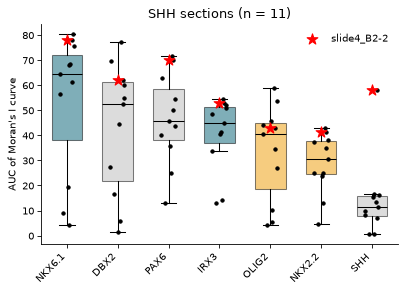

In [10]:
auc_sec = auc_from_profile(prof_all[prof_all["condition"] == "SHH"].drop(columns="condition"))
auc_sec.to_csv(FIG_DIR / "moran_auc_shh_per_section.csv", index=False)

order = auc_sec.groupby("feature")["auc"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(5.5, 4))
for i, g in enumerate(order):
    v = auc_sec.loc[auc_sec["feature"] == g, "auc"].dropna()
    ax.boxplot(v, positions=[i], widths=0.6, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=gene_color(g), alpha=0.5), medianprops=dict(color="k"))
    ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), v, s=10, color="k", zorder=3)
    ex = auc_sec.loc[(auc_sec["feature"] == g) & (auc_sec["library"] == SLIDE), "auc"]
    ax.scatter([i], ex, marker="*", s=120, color="red", zorder=4, label=SLIDE if i == 0 else None)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_ylabel("AUC of Moran's I curve")
ax.set_title(f"SHH sections (n = {auc_sec['library'].nunique()})")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "moran_auc_shh_per_section.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()